In [38]:
# 1. Install only missing packages
for (pkg in c("tidyverse", "readxl", "janitor", "skimr")) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  }
}

library(tidyverse)
library(readxl)
library(janitor)
library(skimr)

# 2. Download & unzip UCI Online Retail dataset if not already in /content
if (!file.exists("Online Retail.xlsx")) {
  download.file(
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip",
    destfile = "online_retail.zip",
    mode = "wb"
  )
  unzip("online_retail.zip")
}

list.files()

[1] "Online Retail.xlsx" "online_retail.zip"  "sample_data"

In [39]:
# Read the Excel dataset into a tibble
raw_retail <- read_excel("Online Retail.xlsx")

# Check dimensions (rows, columns) and column names
cat("Dimensions (rows, cols):", dim(raw_retail), "\n")
cat("Column names:\n")
print(names(raw_retail))

# Inspect first 6 and last 6 rows
head(raw_retail)
tail(raw_retail)

Dimensions (rows, cols): 541909 8 
Column names:
[1] "InvoiceNo"   "StockCode"   "Description" "Quantity"    "InvoiceDate"
[6] "UnitPrice"   "CustomerID"  "Country"    


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom


InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680,France
581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


In [40]:
# 1. Column types & sample values
glimpse(raw_retail)

# 2. Numeric & date summary
summary(raw_retail)

# 3. Missing values per column (count and %)
missing_summary <- tibble(
  column      = names(raw_retail),
  missing_n   = colSums(is.na(raw_retail)),
  missing_pct = round(colMeans(is.na(raw_retail)) * 100, 2)
)
print(missing_summary)

# 4. Unique identifier counts
raw_retail %>%
  summarise(
    unique_invoices  = n_distinct(InvoiceNo, na.rm = TRUE),
    unique_products  = n_distinct(StockCode, na.rm = TRUE),
    unique_customers = n_distinct(CustomerID, na.rm = TRUE),
    unique_countries = n_distinct(Country, na.rm = TRUE)
  )

Rows: 541,909
Columns: 8
$ InvoiceNo   <chr> "536365", "536365", "536365", "536365", "536365", "536365"…
$ StockCode   <chr> "85123A", "71053", "84406B", "84029G", "84029E", "22752", …
$ Description <chr> "WHITE HANGING HEART T-LIGHT HOLDER", "WHITE METAL LANTERN…
$ Quantity    <dbl> 6, 6, 8, 6, 6, 2, 6, 6, 6, 32, 6, 6, 8, 6, 6, 3, 2, 3, 3, …
$ InvoiceDate <dttm> 2010-12-01 08:26:00, 2010-12-01 08:26:00, 2010-12-01 08:2…
$ UnitPrice   <dbl> 2.55, 3.39, 2.75, 3.39, 3.39, 7.65, 4.25, 1.85, 1.85, 1.69…
$ CustomerID  <dbl> 17850, 17850, 17850, 17850, 17850, 17850, 17850, 17850, 17…
$ Country     <chr> "United Kingdom", "United Kingdom", "United Kingdom", "Uni…


     InvoiceNo          StockCode         Description        Quantity         
 Length   :541909   Length   :541909   Length   :541909   Min.   :-80995.000  
 N.unique : 25900   N.unique :  4070   N.unique :  4211   1st Qu.:     1.000  
 N.blank  :     0   N.blank  :     0   N.blank  :     0   Median :     3.000  
 Min.nchar:     6   Min.nchar:     1   Min.nchar:     1   Mean   :     9.552  
 Max.nchar:     7   Max.nchar:    12   Max.nchar:    35   3rd Qu.:    10.000  
                                       NAs      :  1454   Max.   : 80995.000  
                                                                              
  InvoiceDate                    UnitPrice            CustomerID    
 Min.   :2010-12-01 08:26:00   Min.   :-11062.060   Min.   :12346   
 1st Qu.:2011-03-28 11:34:00   1st Qu.:     1.250   1st Qu.:13953   
 Median :2011-07-19 17:17:00   Median :     2.080   Median :15152   
 Mean   :2011-07-04 13:34:57   Mean   :     4.611   Mean   :15288   
 3rd Qu.:2011-10-19 11:

# A tibble: 8 × 3
  column      missing_n missing_pct
  <chr>           <dbl>       <dbl>
1 InvoiceNo           0        0   
2 StockCode           0        0   
3 Description      1454        0.27
4 Quantity            0        0   
5 InvoiceDate         0        0   
6 UnitPrice           0        0   
7 CustomerID     135080       24.9 
8 Country             0        0   


unique_invoices,unique_products,unique_customers,unique_countries
<int>,<int>,<int>,<int>
25900,4070,4372,38


In [23]:
# 1. Standardize column names to snake_case and treat customer_id as character
retail_std <- raw_retail %>%
  clean_names() %>%
  mutate(customer_id = as.character(customer_id))

cat("Cleaned column names:\n")
print(names(retail_std))

# 2. Count exact duplicate rows
n_dupes <- sum(duplicated(retail_std))
cat("Exact duplicate rows:", n_dupes, "\n")

# 3. Preview a few duplicate rows
retail_std %>%
  filter(duplicated(.) | duplicated(., fromLast = TRUE)) %>%
  arrange(invoice_no, stock_code) %>%
  head(10)

Cleaned column names:
[1] "invoice_no"   "stock_code"   "description"  "quantity"     "invoice_date"
[6] "unit_price"   "customer_id"  "country"     
Exact duplicate rows: 5268 


invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>
536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920,United Kingdom


In [41]:
# 1. Remove exact duplicates
retail_dedup <- retail_std %>%
  distinct()

cat("Rows before dedup:", nrow(retail_std), "\n")
cat("Rows after dedup :", nrow(retail_dedup), "\n")
cat("Removed          :", nrow(retail_std) - nrow(retail_dedup), "\n\n")

# 2. Investigate cancellations, negative/zero quantities, and zero/negative prices
retail_dedup %>%
  summarise(
    total_rows         = n(),
    cancel_invoice_C   = sum(str_starts(invoice_no, "C"), na.rm = TRUE),
    qty_le_zero        = sum(quantity <= 0, na.rm = TRUE),
    price_lt_zero      = sum(unit_price < 0, na.rm = TRUE),
    price_eq_zero      = sum(unit_price == 0, na.rm = TRUE),
    missing_customer   = sum(is.na(customer_id))
  )

# 3. Preview negative unit_price rows (if any) and non-C negative quantity rows
cat("\nRows with unit_price < 0:\n")
retail_dedup %>% filter(unit_price < 0)

cat("\nSample rows with quantity <= 0 and NOT starting with 'C':\n")
retail_dedup %>%
  filter(quantity <= 0 & !str_starts(invoice_no, "C")) %>%
  head(10)

Rows before dedup: 541909 
Rows after dedup : 536641 
Removed          : 5268 



total_rows,cancel_invoice_C,qty_le_zero,price_lt_zero,price_eq_zero,missing_customer
<int>,<int>,<int>,<int>,<int>,<int>
536641,9251,10587,2,2510,135037



Rows with unit_price < 0:


invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>
A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NA,United Kingdom
A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NA,United Kingdom



Sample rows with quantity <= 0 and NOT starting with 'C':


invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>
536589,21777,NA,-10,2010-12-01 16:50:00,0,NA,United Kingdom
536764,84952C,NA,-38,2010-12-02 14:42:00,0,NA,United Kingdom
536996,22712,NA,-20,2010-12-03 15:30:00,0,NA,United Kingdom
536997,22028,NA,-20,2010-12-03 15:30:00,0,NA,United Kingdom
536998,85067,NA,-6,2010-12-03 15:30:00,0,NA,United Kingdom
537000,21414,NA,-22,2010-12-03 15:32:00,0,NA,United Kingdom
537001,21653,NA,-6,2010-12-03 15:33:00,0,NA,United Kingdom
537003,85126,NA,-2,2010-12-03 15:33:00,0,NA,United Kingdom
537004,21814,NA,-30,2010-12-03 15:34:00,0,NA,United Kingdom


... (2 outputs left out)


Rows with unit_price < 0:


invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>
A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NA,United Kingdom
A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NA,United Kingdom



Sample rows with quantity <= 0 and NOT starting with 'C':


invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<chr>,<chr>
536589,21777,NA,-10,2010-12-01 16:50:00,0,NA,United Kingdom
536764,84952C,NA,-38,2010-12-02 14:42:00,0,NA,United Kingdom
536996,22712,NA,-20,2010-12-03 15:30:00,0,NA,United Kingdom
536997,22028,NA,-20,2010-12-03 15:30:00,0,NA,United Kingdom
536998,85067,NA,-6,2010-12-03 15:30:00,0,NA,United Kingdom
537000,21414,NA,-22,2010-12-03 15:32:00,0,NA,United Kingdom
537001,21653,NA,-6,2010-12-03 15:33:00,0,NA,United Kingdom
537003,85126,NA,-2,2010-12-03 15:33:00,0,NA,United Kingdom
537004,21814,NA,-30,2010-12-03 15:34:00,0,NA,United Kingdom


In [42]:
# 1. Counts of cancellations, non-positive quantities, and non-positive prices
anomaly_summary <- retail_dedup %>%
  summarise(
    total_rows       = n(),
    cancel_invoice_C = sum(str_starts(invoice_no, "C"), na.rm = TRUE),
    qty_le_zero      = sum(quantity <= 0, na.rm = TRUE),
    price_lt_zero    = sum(unit_price < 0, na.rm = TRUE),
    price_eq_zero    = sum(unit_price == 0, na.rm = TRUE),
    missing_customer = sum(is.na(customer_id))
  )
print(anomaly_summary)

# 2. Rows with negative unit_price
cat("\n--- unit_price < 0 ---\n")
print(retail_dedup %>% filter(unit_price < 0))

# 3. Sample rows with quantity <= 0 and NOT starting with 'C'
cat("\n--- quantity <= 0 & NOT 'C' ---\n")
print(
  retail_dedup %>%
    filter(quantity <= 0 & !str_starts(invoice_no, "C")) %>%
    head(10)
)

# A tibble: 1 × 6
  total_rows cancel_invoice_C qty_le_zero price_lt_zero price_eq_zero
       <int>            <int>       <int>         <int>         <int>
1     536641             9251       10587             2          2510
# ℹ 1 more variable: missing_customer <int>

--- unit_price < 0 ---
# A tibble: 2 × 8
  invoice_no stock_code description     quantity invoice_date        unit_price
  <chr>      <chr>      <chr>              <dbl> <dttm>                   <dbl>
1 A563186    B          Adjust bad debt        1 2011-08-12 14:51:00    -11062.
2 A563187    B          Adjust bad debt        1 2011-08-12 14:52:00    -11062.
# ℹ 2 more variables: customer_id <chr>, country <chr>

--- quantity <= 0 & NOT 'C' ---
# A tibble: 10 × 8
   invoice_no stock_code description quantity invoice_date        unit_price
   <chr>      <chr>      <chr>          <dbl> <dttm>                   <dbl>
 1 536589     21777      NA               -10 2010-12-01 16:50:00          0
 2 536764     84952C     NA 

In [43]:
# 1. Build clean sales dataset + line-level sales_value
retail_sales <- retail_dedup %>%
  filter(
    !str_starts(invoice_no, "C"),
    quantity > 0,
    unit_price > 0
  ) %>%
  mutate(
    sales_value   = quantity * unit_price,
    invoice_day   = as.Date(invoice_date),
    invoice_month = floor_date(invoice_date, unit = "month")
  )

# 2. Build customer-identified dataset for RFM & clustering
retail_customers <- retail_sales %>%
  filter(!is.na(customer_id))

# 3. Data-quality audit table (before vs. after)
cleaning_audit <- tibble(
  stage = c(
    "1. Raw dataset",
    "2. After removing exact duplicates",
    "3. Valid sales (qty > 0, unit_price > 0, non-C)",
    "4. Valid sales with known customer_id (RFM base)"
  ),
  rows = c(
    nrow(raw_retail),
    nrow(retail_dedup),
    nrow(retail_sales),
    nrow(retail_customers)
  ),
  rows_removed_from_prev = c(
    0,
    nrow(raw_retail) - nrow(retail_dedup),
    nrow(retail_dedup) - nrow(retail_sales),
    nrow(retail_sales) - nrow(retail_customers)
  )
)

print(cleaning_audit)

# A tibble: 4 × 3
  stage                                              rows rows_removed_from_prev
  <chr>                                             <int>                  <dbl>
1 1. Raw dataset                                   541909                      0
2 2. After removing exact duplicates               536641                   5268
3 3. Valid sales (qty > 0, unit_price > 0, non-C)  524878                  11763
4 4. Valid sales with known customer_id (RFM base) 392692                 132186
# A tibble: 4 × 3
  stage                                              rows rows_removed_from_prev
  <chr>                                             <int>                  <dbl>
1 1. Raw dataset                                   541909                      0
2 2. After removing exact duplicates               536641                   5268
3 3. Valid sales (qty > 0, unit_price > 0, non-C)  524878                  11763
4 4. Valid sales with known customer_id (RFM base) 392692                

# A tibble: 1 × 5
  total_sales_gbp n_invoices n_customers_known n_products avg_invoice_gbp
            <dbl>      <int>             <int>      <int>           <dbl>
1       10642111.      19960              4338       3922            533.
# A tibble: 13 × 3
   invoice_month       monthly_revenue n_invoices
   <dttm>                        <dbl>      <int>
 1 2010-12-01 00:00:00         821453.       1559
 2 2011-01-01 00:00:00         689812.       1086
 3 2011-02-01 00:00:00         522546.       1100
 4 2011-03-01 00:00:00         716215.       1454
 5 2011-04-01 00:00:00         536968.       1246
 6 2011-05-01 00:00:00         769297.       1681
 7 2011-06-01 00:00:00         760547.       1533
 8 2011-07-01 00:00:00         718076.       1475
 9 2011-08-01 00:00:00         757841.       1361
10 2011-09-01 00:00:00        1056435.       1837
11 2011-10-01 00:00:00        1151264.       2040
12 2011-11-01 00:00:00        1503867.       2769
13 2011-12-01 00:00:00         637790.   

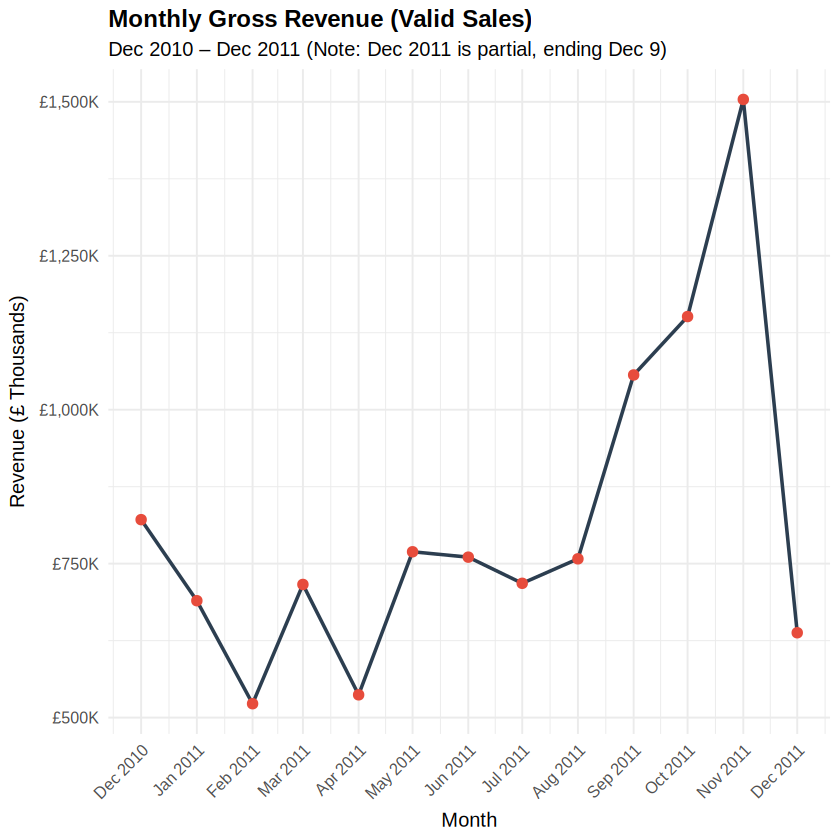

# A tibble: 1 × 5
  total_sales_gbp n_invoices n_customers_known n_products avg_invoice_gbp
            <dbl>      <int>             <int>      <int>           <dbl>
1       10642111.      19960              4338       3922            533.
# A tibble: 13 × 3
   invoice_month       monthly_revenue n_invoices
   <dttm>                        <dbl>      <int>
 1 2010-12-01 00:00:00         821453.       1559
 2 2011-01-01 00:00:00         689812.       1086
 3 2011-02-01 00:00:00         522546.       1100
 4 2011-03-01 00:00:00         716215.       1454
 5 2011-04-01 00:00:00         536968.       1246
 6 2011-05-01 00:00:00         769297.       1681
 7 2011-06-01 00:00:00         760547.       1533
 8 2011-07-01 00:00:00         718076.       1475
 9 2011-08-01 00:00:00         757841.       1361
10 2011-09-01 00:00:00        1056435.       1837
11 2011-10-01 00:00:00        1151264.       2040
12 2011-11-01 00:00:00        1503867.       2769
13 2011-12-01 00:00:00         637790.   

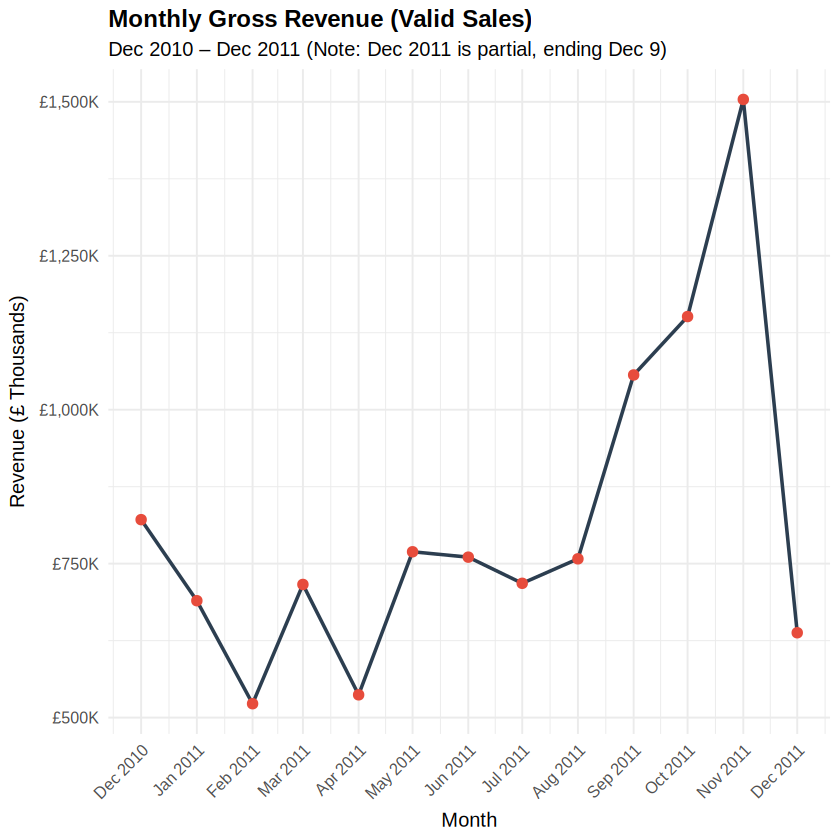

In [44]:
library(scales)

# Consistent theme for all EDA plots
theme_retail <- theme_minimal(base_size = 12) +
  theme(
    plot.title = element_text(face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

# 3A. Overall Sales KPIs (on valid sales)
sales_overview <- retail_sales %>%
  summarise(
    total_sales_gbp   = sum(sales_value),
    n_invoices        = n_distinct(invoice_no),
    n_customers_known = n_distinct(customer_id, na.rm = TRUE),
    n_products        = n_distinct(stock_code),
    avg_invoice_gbp   = total_sales_gbp / n_invoices
  )
print(sales_overview)

# 3B. Monthly Sales Aggregation
monthly_sales <- retail_sales %>%
  group_by(invoice_month) %>%
  summarise(
    monthly_revenue = sum(sales_value),
    n_invoices      = n_distinct(invoice_no),
    .groups = "drop"
  ) %>%
  arrange(invoice_month)
print(monthly_sales)

# Plot 1: Monthly Revenue Line Chart
ggplot(monthly_sales, aes(x = invoice_month, y = monthly_revenue)) +
  geom_line(color = "#2C3E50", linewidth = 1) +
  geom_point(color = "#E74C3C", size = 2.5) +
  scale_x_datetime(date_breaks = "1 month", date_labels = "%b %Y") +
  scale_y_continuous(labels = label_dollar(prefix = "£", scale = 1e-3, suffix = "K")) +
  labs(
    title    = "Monthly Gross Revenue (Valid Sales)",
    subtitle = "Dec 2010 – Dec 2011 (Note: Dec 2011 is partial, ending Dec 9)",
    x        = "Month",
    y        = "Revenue (£ Thousands)"
  ) +
  theme_retail

--- Top 10 Products by Revenue ---
# A tibble: 10 × 5
   stock_code description                     total_revenue total_qty n_invoices
   <chr>      <chr>                                   <dbl>     <dbl>      <int>
 1 DOT        DOTCOM POSTAGE                        206249.       706        706
 2 22423      REGENCY CAKESTAND 3 TIER              174157.     13851       1988
 3 23843      PAPER CRAFT , LITTLE BIRDIE           168470.     80995          1
 4 85123A     WHITE HANGING HEART T-LIGHT HO…       104284.     37580       2189
 5 47566      PARTY BUNTING                          99445.     18283       1685
 6 85099B     JUMBO BAG RED RETROSPOT                94160.     48371       2089
 7 23166      MEDIUM CERAMIC TOP STORAGE JAR         81701.     78033        247
 8 POST       POSTAGE                                78102.      3150       1126
 9 M          Manual                                 77750.      6984        289
10 23084      RABBIT NIGHT LIGHT                     66

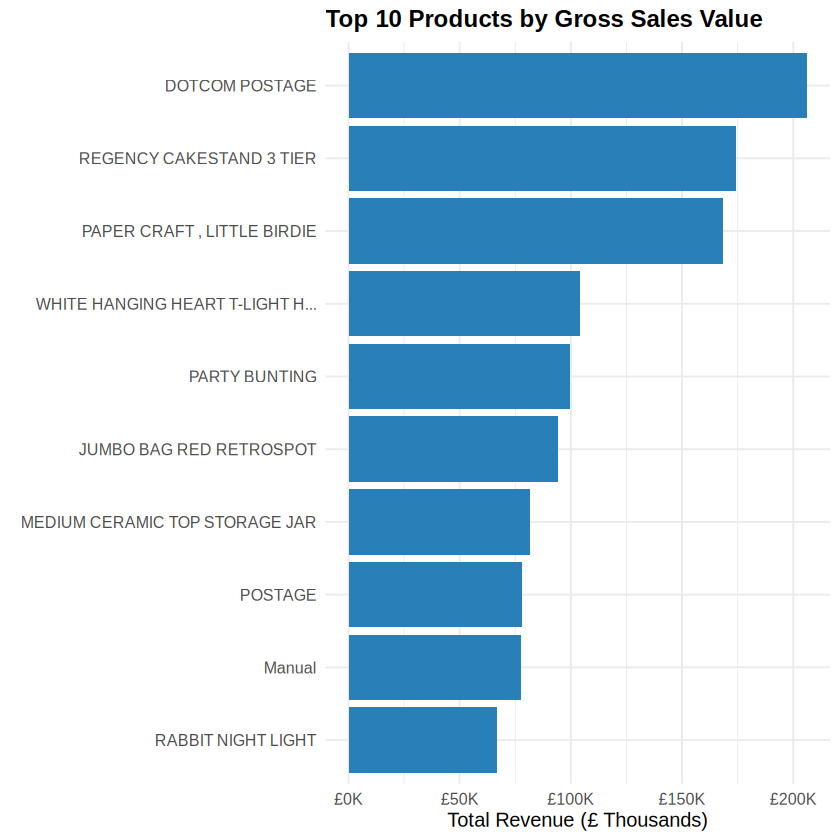

--- Top 10 Products by Revenue ---
# A tibble: 10 × 5
   stock_code description                     total_revenue total_qty n_invoices
   <chr>      <chr>                                   <dbl>     <dbl>      <int>
 1 DOT        DOTCOM POSTAGE                        206249.       706        706
 2 22423      REGENCY CAKESTAND 3 TIER              174157.     13851       1988
 3 23843      PAPER CRAFT , LITTLE BIRDIE           168470.     80995          1
 4 85123A     WHITE HANGING HEART T-LIGHT HO…       104284.     37580       2189
 5 47566      PARTY BUNTING                          99445.     18283       1685
 6 85099B     JUMBO BAG RED RETROSPOT                94160.     48371       2089
 7 23166      MEDIUM CERAMIC TOP STORAGE JAR         81701.     78033        247
 8 POST       POSTAGE                                78102.      3150       1126
 9 M          Manual                                 77750.      6984        289
10 23084      RABBIT NIGHT LIGHT                     66

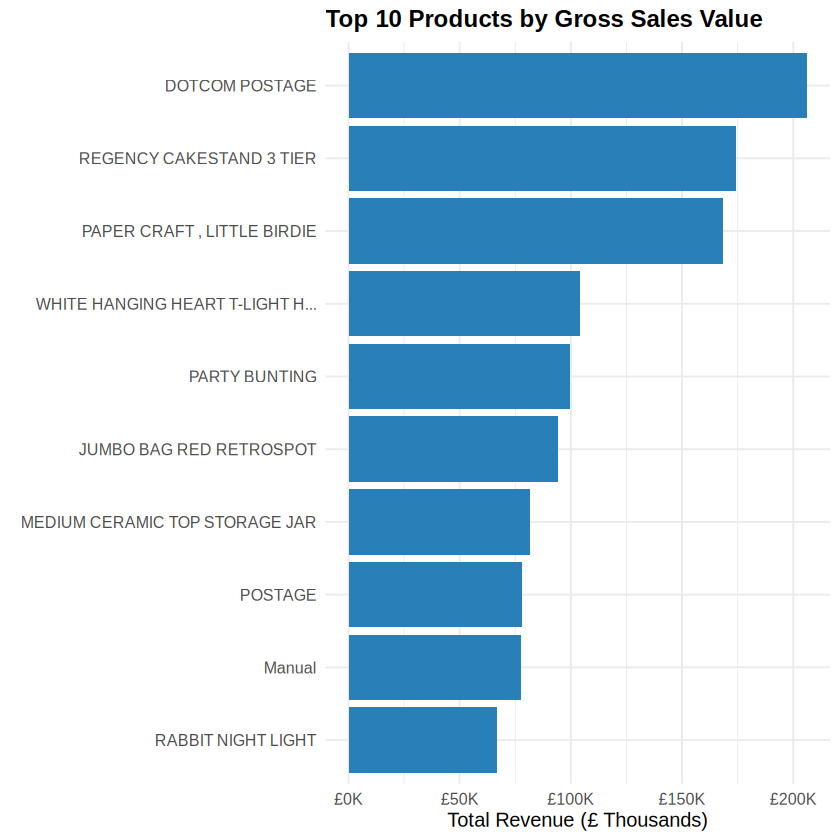

In [45]:
# Aggregate by product (stock_code + description)
product_summary <- retail_sales %>%
  group_by(stock_code, description) %>%
  summarise(
    total_revenue = sum(sales_value),
    total_qty     = sum(quantity),
    n_invoices    = n_distinct(invoice_no),
    .groups       = "drop"
  )

# Top 10 by revenue
top10_rev <- product_summary %>%
  slice_max(total_revenue, n = 10)
cat("--- Top 10 Products by Revenue ---\n")
print(top10_rev)

# Top 10 by quantity
top10_qty <- product_summary %>%
  slice_max(total_qty, n = 10)
cat("\n--- Top 10 Products by Quantity ---\n")
print(top10_qty)

# Plot 2: Top 10 Products by Sales Value
ggplot(top10_rev, aes(x = reorder(str_trunc(description, 32), total_revenue), y = total_revenue)) +
  geom_col(fill = "#2980B9") +
  coord_flip() +
  scale_y_continuous(labels = label_dollar(prefix = "£", scale = 1e-3, suffix = "K")) +
  labs(
    title = "Top 10 Products by Gross Sales Value",
    x     = NULL,
    y     = "Total Revenue (£ Thousands)"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

--- Top 10 Countries by Revenue ---
# A tibble: 10 × 5
   country        total_revenue n_invoices n_customers_known revenue_share_pct
   <chr>                  <dbl>      <int>             <int>             <dbl>
 1 United Kingdom      9001744.      18019              3920             84.6 
 2 Netherlands          285446.         94                 9              2.68
 3 EIRE                 283141.        288                 3              2.66
 4 Germany              228678.        457                94              2.15
 5 France               209625.        392                87              1.97
 6 Australia            138454.         57                 9              1.3 
 7 Spain                 61559.         90                30              0.58
 8 Switzerland           57068.         54                21              0.54
 9 Belgium               41196.         98                25              0.39
10 Sweden                38368.         36                 8              0.

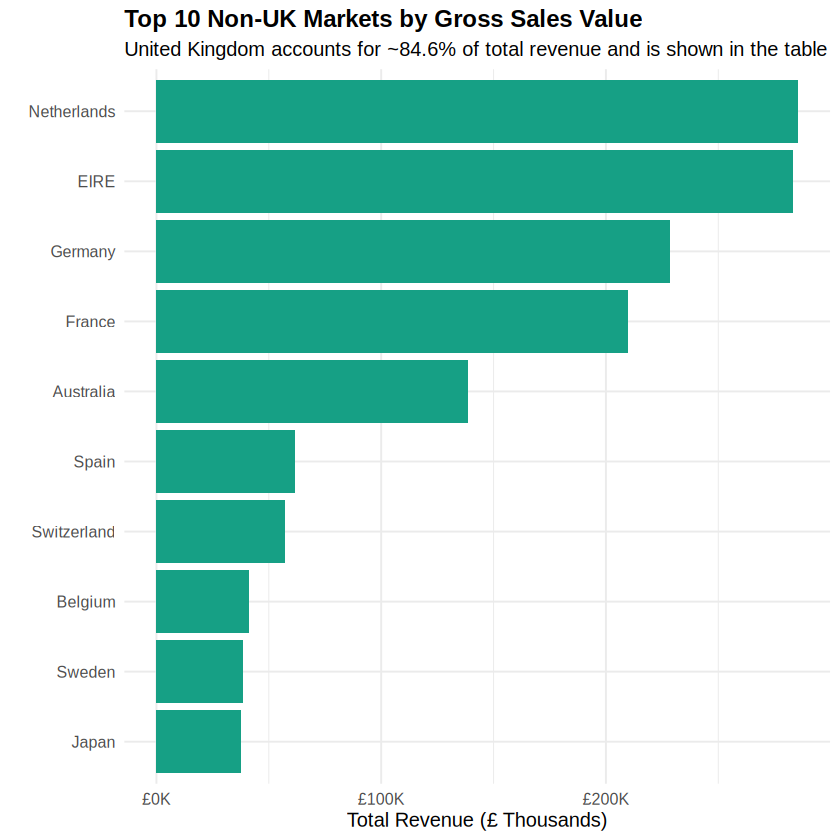

--- Top 10 Countries by Revenue ---
# A tibble: 10 × 5
   country        total_revenue n_invoices n_customers_known revenue_share_pct
   <chr>                  <dbl>      <int>             <int>             <dbl>
 1 United Kingdom      9001744.      18019              3920             84.6 
 2 Netherlands          285446.         94                 9              2.68
 3 EIRE                 283141.        288                 3              2.66
 4 Germany              228678.        457                94              2.15
 5 France               209625.        392                87              1.97
 6 Australia            138454.         57                 9              1.3 
 7 Spain                 61559.         90                30              0.58
 8 Switzerland           57068.         54                21              0.54
 9 Belgium               41196.         98                25              0.39
10 Sweden                38368.         36                 8              0.

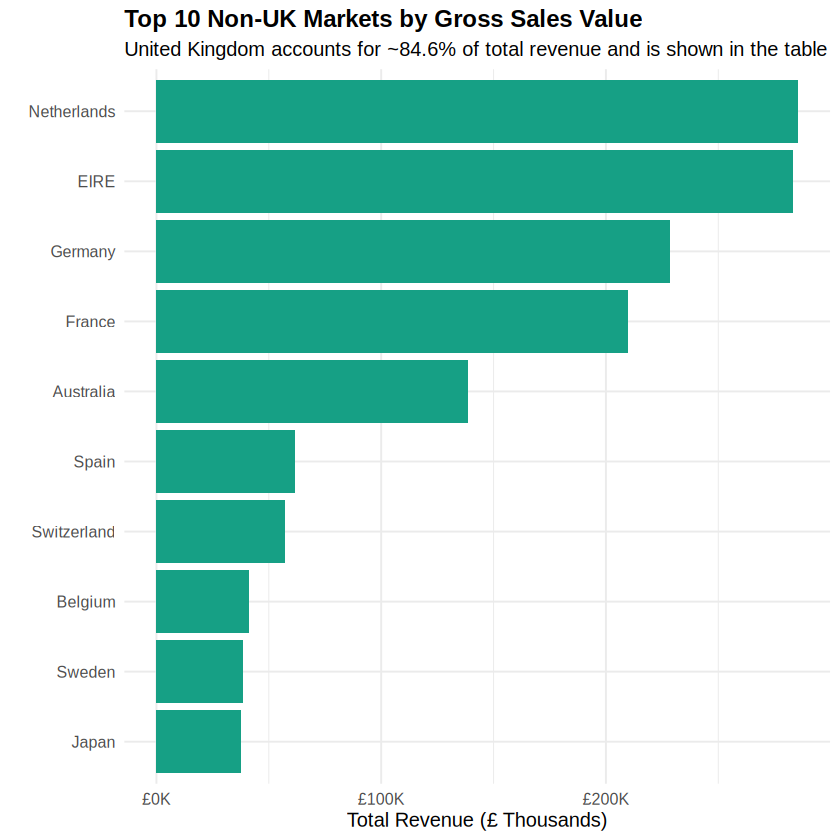

In [46]:
# Aggregate sales, invoices, and identified customers by country
country_summary <- retail_sales %>%
  group_by(country) %>%
  summarise(
    total_revenue     = sum(sales_value),
    n_invoices        = n_distinct(invoice_no),
    n_customers_known = n_distinct(customer_id, na.rm = TRUE),
    revenue_share_pct = round(sum(sales_value) / sum(retail_sales$sales_value) * 100, 2),
    .groups           = "drop"
  ) %>%
  arrange(desc(total_revenue))

cat("--- Top 10 Countries by Revenue ---\n")
print(head(country_summary, 10))

# Plot 3: Top 10 Countries EXCLUDING United Kingdom (so non-UK markets are readable)
country_summary %>%
  filter(country != "United Kingdom") %>%
  slice_max(total_revenue, n = 10) %>%
  ggplot(aes(x = reorder(country, total_revenue), y = total_revenue)) +
  geom_col(fill = "#16A085") +
  coord_flip() +
  scale_y_continuous(labels = label_dollar(prefix = "£", scale = 1e-3, suffix = "K")) +
  labs(
    title    = "Top 10 Non-UK Markets by Gross Sales Value",
    subtitle = "United Kingdom accounts for ~84.6% of total revenue and is shown in the table",
    x        = NULL,
    y        = "Total Revenue (£ Thousands)"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

--- Top 10 Countries by Revenue ---
# A tibble: 10 × 5
   country        total_revenue n_invoices n_customers_known revenue_share_pct
   <chr>                  <dbl>      <int>             <int>             <dbl>
 1 United Kingdom      9001744.      18019              3920             84.6 
 2 Netherlands          285446.         94                 9              2.68
 3 EIRE                 283141.        288                 3              2.66
 4 Germany              228678.        457                94              2.15
 5 France               209625.        392                87              1.97
 6 Australia            138454.         57                 9              1.3 
 7 Spain                 61559.         90                30              0.58
 8 Switzerland           57068.         54                21              0.54
 9 Belgium               41196.         98                25              0.39
10 Sweden                38368.         36                 8              0.

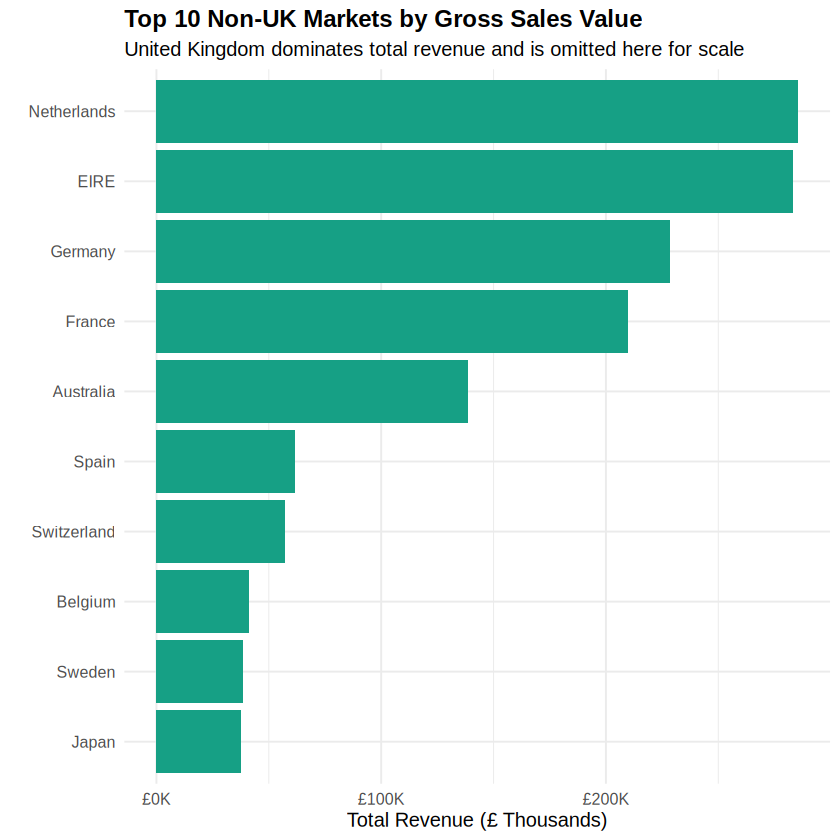

--- Top 10 Countries by Revenue ---
# A tibble: 10 × 5
   country        total_revenue n_invoices n_customers_known revenue_share_pct
   <chr>                  <dbl>      <int>             <int>             <dbl>
 1 United Kingdom      9001744.      18019              3920             84.6 
 2 Netherlands          285446.         94                 9              2.68
 3 EIRE                 283141.        288                 3              2.66
 4 Germany              228678.        457                94              2.15
 5 France               209625.        392                87              1.97
 6 Australia            138454.         57                 9              1.3 
 7 Spain                 61559.         90                30              0.58
 8 Switzerland           57068.         54                21              0.54
 9 Belgium               41196.         98                25              0.39
10 Sweden                38368.         36                 8              0.

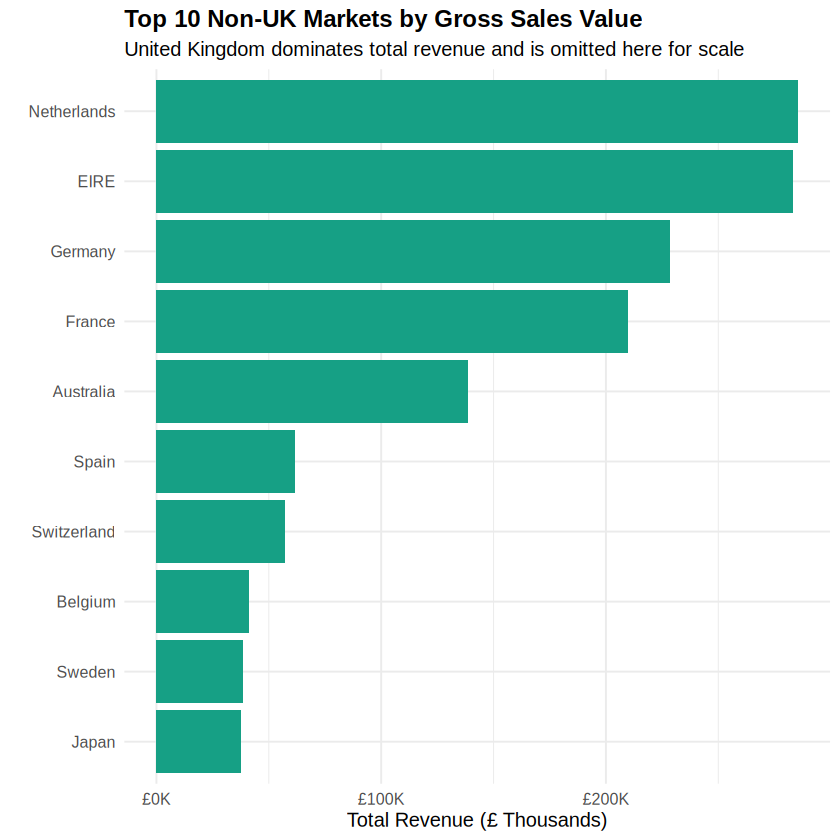

In [47]:
# Aggregate sales, invoices, and identified customers by country
country_summary <- retail_sales %>%
  group_by(country) %>%
  summarise(
    total_revenue     = sum(sales_value),
    n_invoices        = n_distinct(invoice_no),
    n_customers_known = n_distinct(customer_id, na.rm = TRUE),
    revenue_share_pct = round(sum(sales_value) / sum(retail_sales$sales_value) * 100, 2),
    .groups           = "drop"
  ) %>%
  arrange(desc(total_revenue))

cat("--- Top 10 Countries by Revenue ---\n")
print(head(country_summary, 10))

# Plot 3: Top 10 Non-UK Markets (UK omitted so smaller markets remain readable)
country_summary %>%
  filter(country != "United Kingdom") %>%
  slice_max(total_revenue, n = 10) %>%
  ggplot(aes(x = reorder(country, total_revenue), y = total_revenue)) +
  geom_col(fill = "#16A085") +
  coord_flip() +
  scale_y_continuous(labels = label_dollar(prefix = "£", scale = 1e-3, suffix = "K")) +
  labs(
    title    = "Top 10 Non-UK Markets by Gross Sales Value",
    subtitle = "United Kingdom dominates total revenue and is omitted here for scale",
    x        = NULL,
    y        = "Total Revenue (£ Thousands)"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

--- Invoice Value Summary (£) ---
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
     0.38    151.69    303.30    533.17    493.46 168469.60 
Quantiles (50%, 90%, 95%, 99%):
     50%      90%      95%      99% 
 303.300  938.391 1585.921 4821.165 

--- Line-Item Quantity Summary ---
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
    1.00     1.00     4.00    10.62    11.00 80995.00 
Quantiles (50%, 90%, 95%, 99%):
50% 90% 95% 99% 
  4  24  30 100 


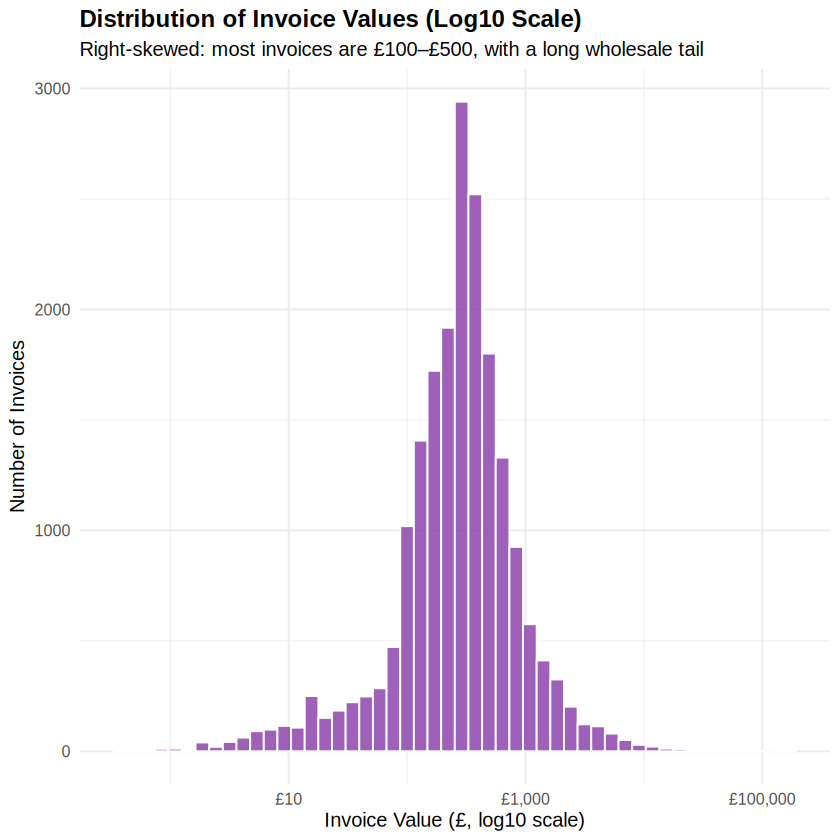

--- Invoice Value Summary (£) ---
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
     0.38    151.69    303.30    533.17    493.46 168469.60 
Quantiles (50%, 90%, 95%, 99%):
     50%      90%      95%      99% 
 303.300  938.391 1585.921 4821.165 

--- Line-Item Quantity Summary ---
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
    1.00     1.00     4.00    10.62    11.00 80995.00 
Quantiles (50%, 90%, 95%, 99%):
50% 90% 95% 99% 
  4  24  30 100 


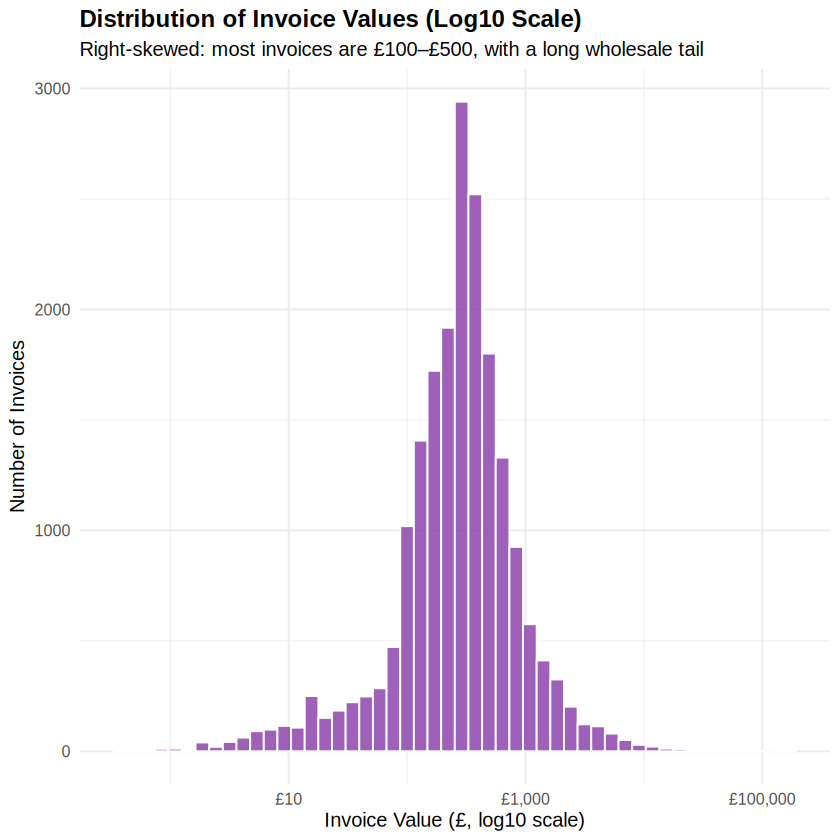

In [48]:
# Aggregate to invoice level
invoice_summary <- retail_sales %>%
  group_by(invoice_no) %>%
  summarise(
    invoice_value = sum(sales_value),
    invoice_qty   = sum(quantity),
    n_lines       = n(),
    .groups       = "drop"
  )

cat("--- Invoice Value Summary (£) ---\n")
print(summary(invoice_summary$invoice_value))
cat("Quantiles (50%, 90%, 95%, 99%):\n")
print(quantile(invoice_summary$invoice_value, probs = c(0.5, 0.9, 0.95, 0.99)))

cat("\n--- Line-Item Quantity Summary ---\n")
print(summary(retail_sales$quantity))
cat("Quantiles (50%, 90%, 95%, 99%):\n")
print(quantile(retail_sales$quantity, probs = c(0.5, 0.9, 0.95, 0.99)))

# Plot 4: Distribution of Invoice Values (log10 x-axis due to heavy right skew)
ggplot(invoice_summary, aes(x = invoice_value)) +
  geom_histogram(bins = 50, fill = "#8E44AD", color = "white", alpha = 0.85) +
  scale_x_log10(labels = label_dollar(prefix = "£")) +
  labs(
    title    = "Distribution of Invoice Values (Log10 Scale)",
    subtitle = "Right-skewed: most invoices are £100–£500, with a long wholesale tail",
    x        = "Invoice Value (£, log10 scale)",
    y        = "Number of Invoices"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

In [49]:
# 1. Define reference date: 1 day after the latest eligible transaction date
ref_date <- max(retail_customers$invoice_day) + 1
cat("Latest transaction date:", as.character(max(retail_customers$invoice_day)), "\n")
cat("RFM reference date     :", as.character(ref_date), "\n\n")

# 2. Compute RFM metrics per customer
rfm <- retail_customers %>%
  group_by(customer_id) %>%
  summarise(
    recency   = as.numeric(ref_date - max(invoice_day)),
    frequency = n_distinct(invoice_no),
    monetary  = sum(sales_value),
    .groups   = "drop"
  )

cat("Total customers in RFM table:", nrow(rfm), "\n\n")
print(head(rfm))

cat("\n--- RFM Summary ---\n")
print(summary(select(rfm, recency, frequency, monetary)))

cat("\n--- RFM Correlations (Pearson) ---\n")
print(round(cor(select(rfm, recency, frequency, monetary)), 3))

Latest transaction date: 2011-12-09 
RFM reference date     : 2011-12-10 

Total customers in RFM table: 4338 

# A tibble: 6 × 4
  customer_id recency frequency monetary
  <chr>         <dbl>     <int>    <dbl>
1 12346           326         1   77184.
2 12347             3         7    4310 
3 12348            76         4    1797.
4 12349            19         1    1758.
5 12350           311         1     334.
6 12352            37         8    2506.

--- RFM Summary ---
    recency         frequency          monetary        
 Min.   :  1.00   Min.   :  1.000   Min.   :     3.75  
 1st Qu.: 18.00   1st Qu.:  1.000   1st Qu.:   306.48  
 Median : 51.00   Median :  2.000   Median :   668.57  
 Mean   : 93.06   Mean   :  4.272   Mean   :  2048.69  
 3rd Qu.:142.75   3rd Qu.:  5.000   3rd Qu.:  1660.60  
 Max.   :374.00   Max.   :209.000   Max.   :280206.02  

--- RFM Correlations (Pearson) ---
          recency frequency monetary
recency     1.000    -0.261   -0.122
frequency  -0.261  

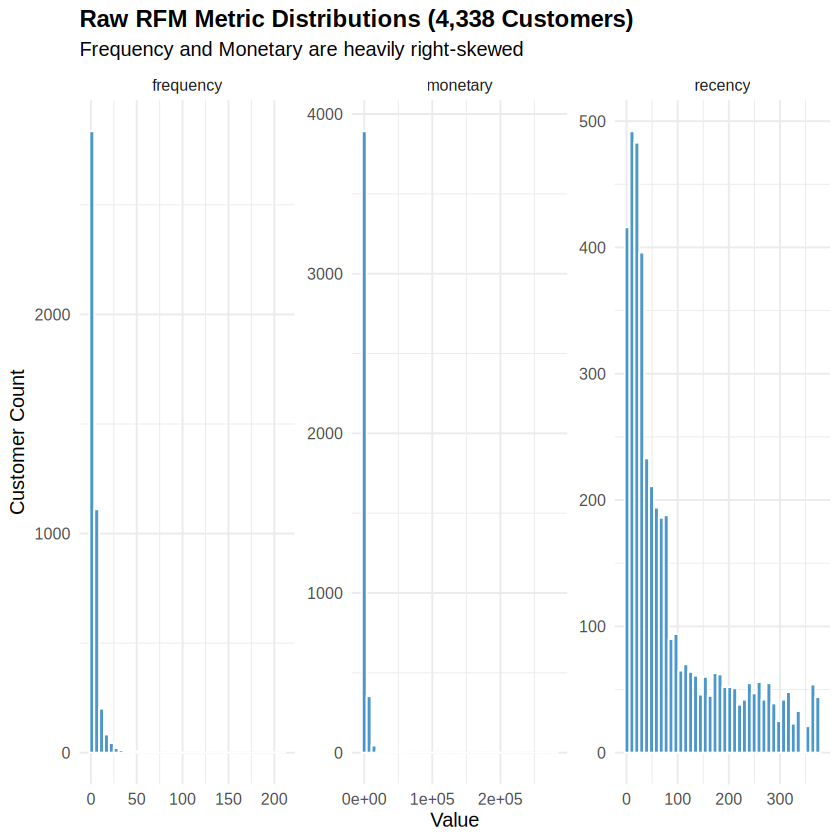

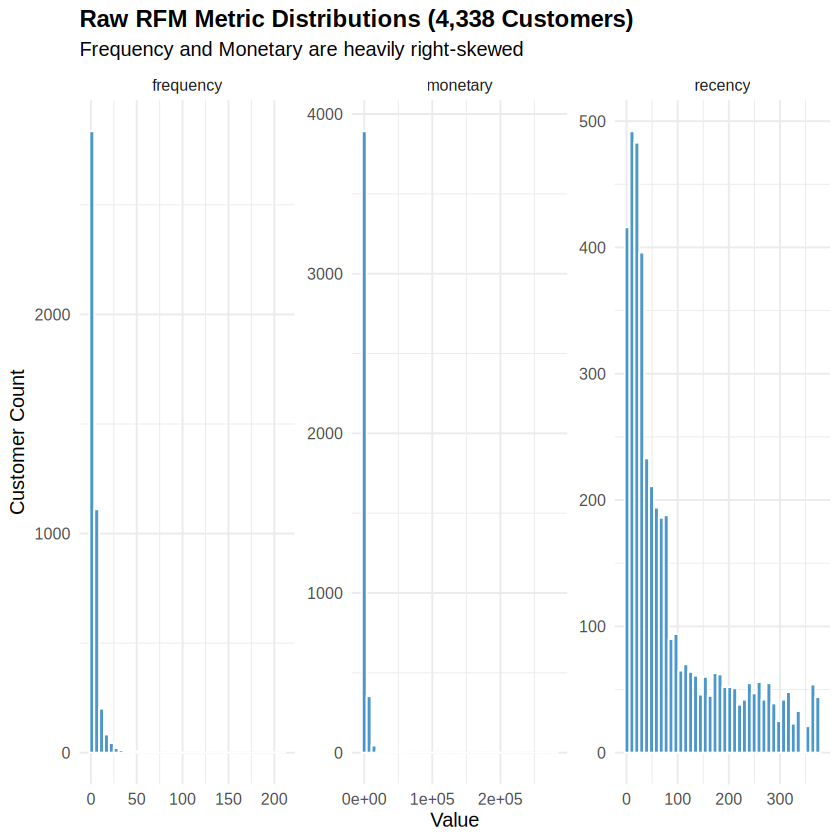

In [50]:
rfm_long <- rfm %>%
  pivot_longer(
    cols      = c(recency, frequency, monetary),
    names_to  = "metric",
    values_to = "value"
  )

ggplot(rfm_long, aes(x = value)) +
  geom_histogram(bins = 40, fill = "#2E86C1", color = "white", alpha = 0.85) +
  facet_wrap(~ metric, scales = "free") +
  labs(
    title    = "Raw RFM Metric Distributions (4,338 Customers)",
    subtitle = "Frequency and Monetary are heavily right-skewed",
    x        = "Value",
    y        = "Customer Count"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

--- Scaled Feature Summary ---
     r_log              f_log             m_log        
 Min.   :-2.42073   Min.   :-0.9551   Min.   :-3.9974  
 1st Qu.:-0.69833   1st Qu.:-0.9551   1st Qu.:-0.6835  
 Median : 0.07196   Median :-0.3615   Median :-0.0651  
 Mean   : 0.00000   Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.84991   3rd Qu.: 0.6532   3rd Qu.: 0.6571  
 Max.   : 1.58350   Max.   : 5.8579   Max.   : 4.7318  
# A tibble: 8 × 3
      k tot_withinss avg_silhouette
  <int>        <dbl>          <dbl>
1     1       13011          NA    
2     2        6475           0.432
3     3        4857.          0.337
4     4        3924.          0.335
5     5        3268.          0.318
6     6        2840.          0.316
7     7        2532.          0.310
8     8        2324.          0.303


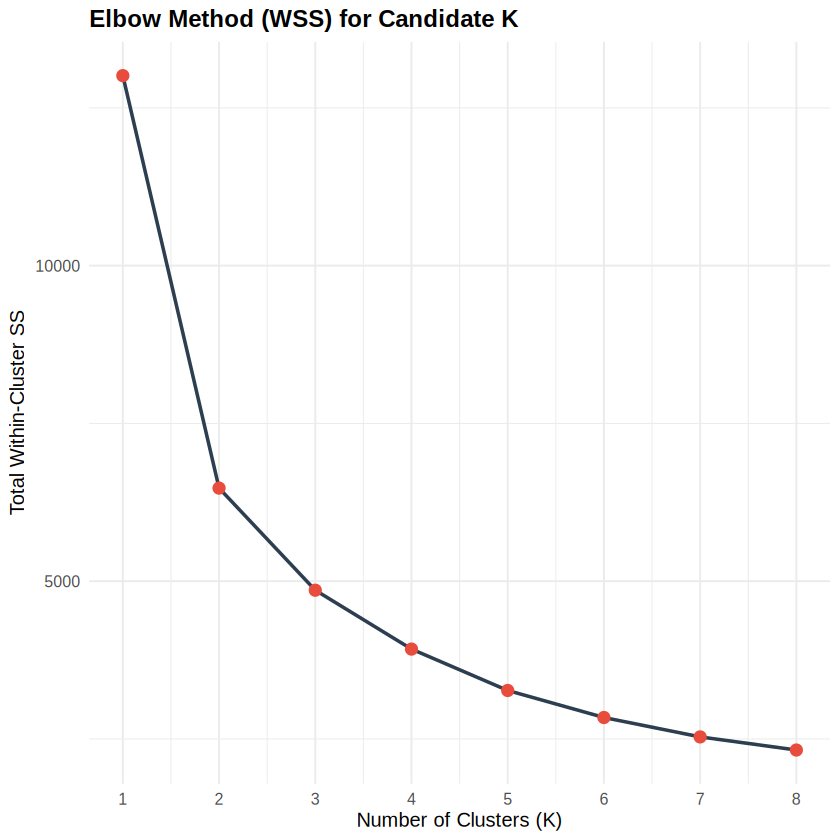

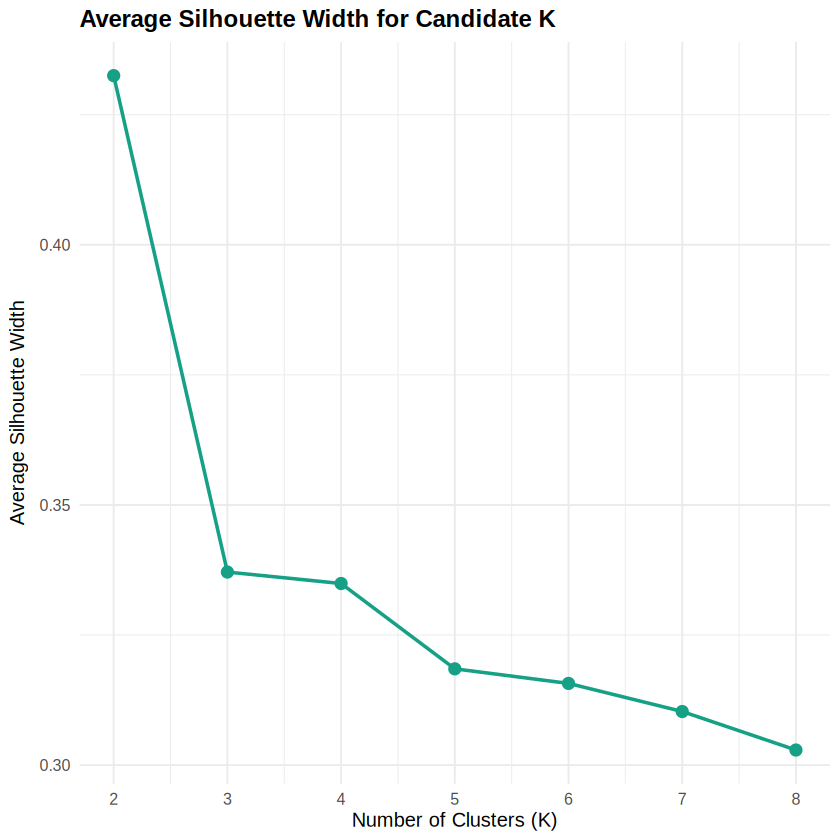

--- Scaled Feature Summary ---
     r_log              f_log             m_log        
 Min.   :-2.42073   Min.   :-0.9551   Min.   :-3.9974  
 1st Qu.:-0.69833   1st Qu.:-0.9551   1st Qu.:-0.6835  
 Median : 0.07196   Median :-0.3615   Median :-0.0651  
 Mean   : 0.00000   Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.84991   3rd Qu.: 0.6532   3rd Qu.: 0.6571  
 Max.   : 1.58350   Max.   : 5.8579   Max.   : 4.7318  
# A tibble: 8 × 3
      k tot_withinss avg_silhouette
  <int>        <dbl>          <dbl>
1     1       13011          NA    
2     2        6475           0.432
3     3        4857.          0.337
4     4        3924.          0.335
5     5        3268.          0.318
6     6        2840.          0.316
7     7        2532.          0.310
8     8        2324.          0.303


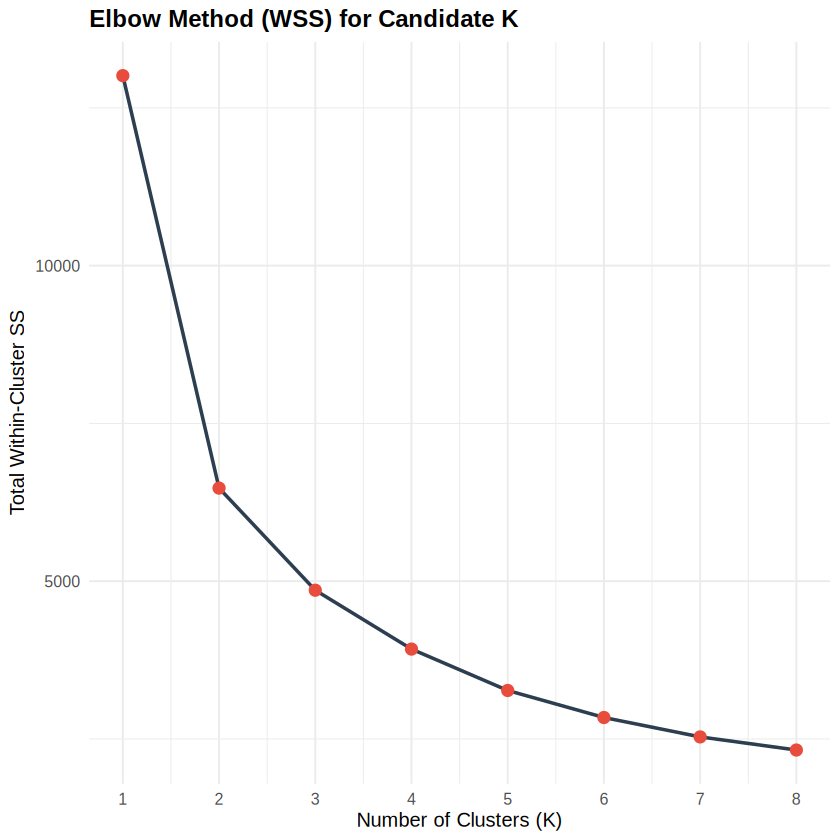

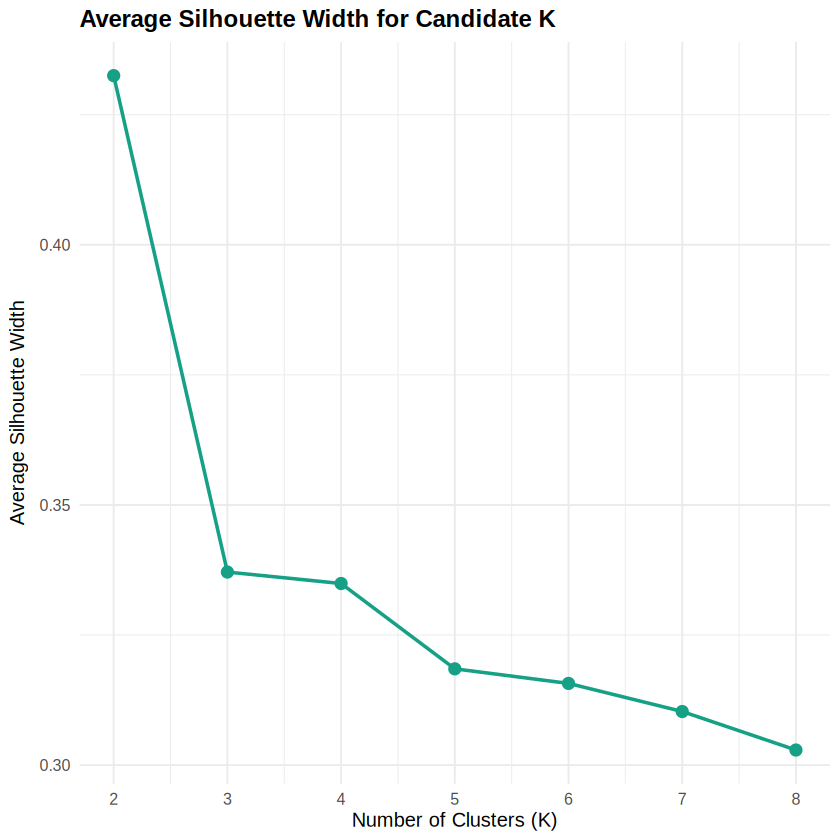

In [51]:
library(cluster)

# 1. Log-transform + standardize RFM features
rfm_scaled <- rfm %>%
  mutate(
    r_log = log1p(recency),
    f_log = log1p(frequency),
    m_log = log1p(monetary)
  ) %>%
  select(r_log, f_log, m_log) %>%
  scale() %>%
  as_tibble()

cat("--- Scaled Feature Summary ---\n")
print(summary(rfm_scaled))

# 2. Compute WSS (Elbow) and Average Silhouette for K = 2..8
dist_mat <- dist(rfm_scaled)

k_eval <- map_dfr(1:8, function(k) {
  set.seed(42)
  km <- kmeans(rfm_scaled, centers = k, nstart = 25)
  avg_sil <- if (k == 1) NA_real_ else mean(silhouette(km$cluster, dist_mat)[, 3])
  tibble(
    k              = k,
    tot_withinss   = round(km$tot.withinss, 1),
    avg_silhouette = round(avg_sil, 4)
  )
})

print(k_eval)

# 3. Elbow Plot
ggplot(k_eval, aes(x = k, y = tot_withinss)) +
  geom_line(color = "#2C3E50", linewidth = 1) +
  geom_point(color = "#E74C3C", size = 3) +
  scale_x_continuous(breaks = 1:8) +
  labs(title = "Elbow Method (WSS) for Candidate K", x = "Number of Clusters (K)", y = "Total Within-Cluster SS") +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

# 4. Silhouette Plot
k_eval %>%
  filter(!is.na(avg_silhouette)) %>%
  ggplot(aes(x = k, y = avg_silhouette)) +
  geom_line(color = "#16A085", linewidth = 1) +
  geom_point(color = "#16A085", size = 3) +
  scale_x_continuous(breaks = 2:8) +
  labs(title = "Average Silhouette Width for Candidate K", x = "Number of Clusters (K)", y = "Average Silhouette Width") +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

Cluster sizes (K = 4):

   1    2    3    4 
1163 1571  728  876 


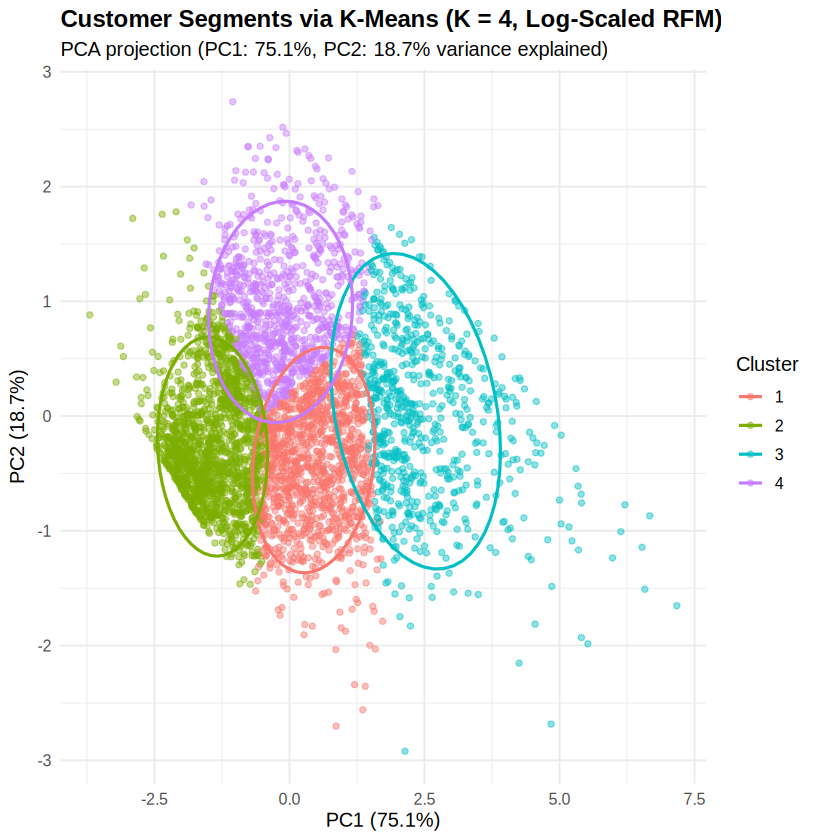

Cluster sizes (K = 4):

   1    2    3    4 
1163 1571  728  876 


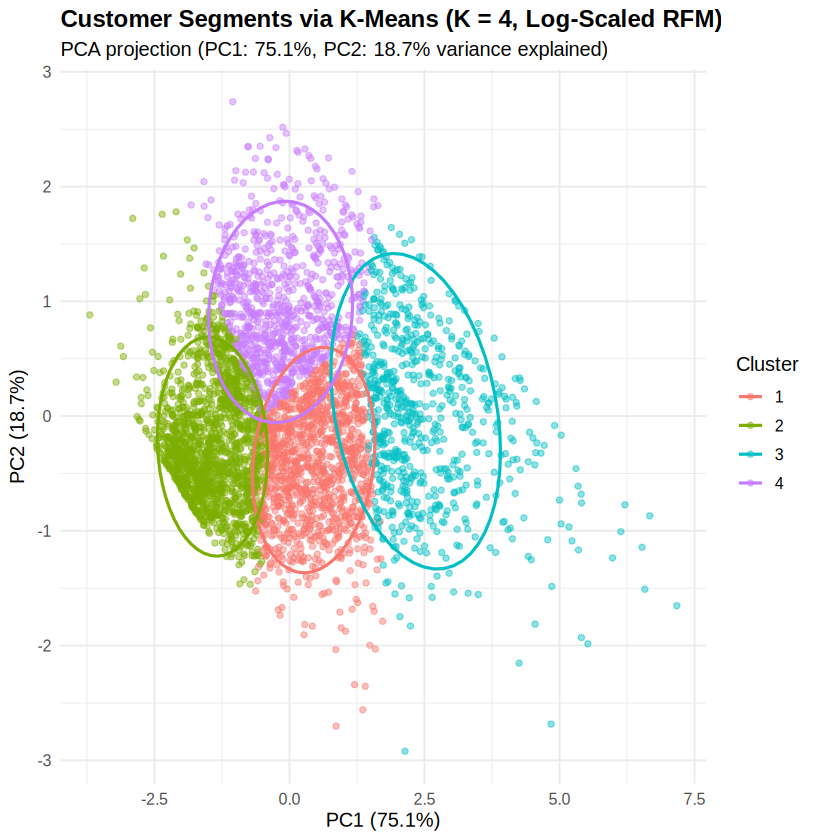

In [52]:
# 1. Fit K-Means with K = 4
set.seed(42)
km_4 <- kmeans(rfm_scaled, centers = 4, nstart = 25)

rfm_clustered <- rfm %>%
  mutate(cluster = factor(km_4$cluster))

cat("Cluster sizes (K = 4):\n")
print(table(rfm_clustered$cluster))

# 2. Compute 2D PCA coordinates for visualization
pca_res <- prcomp(rfm_scaled, center = FALSE, scale. = FALSE)
var_exp <- round(summary(pca_res)$importance[2, 1:2] * 100, 1)

pca_df <- as_tibble(pca_res$x[, 1:2]) %>%
  mutate(cluster = rfm_clustered$cluster)

# Plot clusters in 2D PCA space
ggplot(pca_df, aes(x = PC1, y = PC2, color = cluster)) +
  geom_point(alpha = 0.45, size = 1.4) +
  stat_ellipse(level = 0.90, linewidth = 0.9) +
  labs(
    title    = "Customer Segments via K-Means (K = 4, Log-Scaled RFM)",
    subtitle = paste0("PCA projection (PC1: ", var_exp[1], "%, PC2: ", var_exp[2], "% variance explained)"),
    x        = paste0("PC1 (", var_exp[1], "%)"),
    y        = paste0("PC2 (", var_exp[2], "%)"),
    color    = "Cluster"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"))

# A tibble: 4 × 11
  cluster n_customers customer_share median_recency median_frequency
  <fct>         <int>          <dbl>          <dbl>            <dbl>
1 3               728           16.8              9               10
2 1              1163           26.8             54                4
3 4               876           20.2             19                2
4 2              1571           36.2            184                1
# ℹ 6 more variables: median_monetary <dbl>, mean_recency <dbl>,
#   mean_frequency <dbl>, mean_monetary <dbl>, total_revenue <dbl>,
#   revenue_share <dbl>


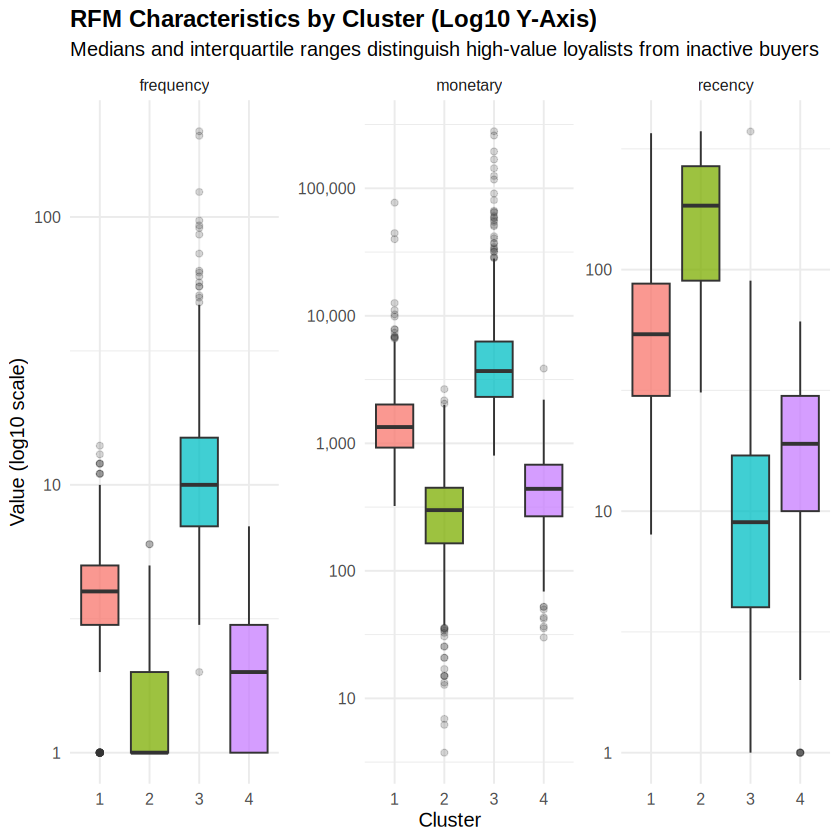

# A tibble: 4 × 11
  cluster n_customers customer_share median_recency median_frequency
  <fct>         <int>          <dbl>          <dbl>            <dbl>
1 3               728           16.8              9               10
2 1              1163           26.8             54                4
3 4               876           20.2             19                2
4 2              1571           36.2            184                1
# ℹ 6 more variables: median_monetary <dbl>, mean_recency <dbl>,
#   mean_frequency <dbl>, mean_monetary <dbl>, total_revenue <dbl>,
#   revenue_share <dbl>


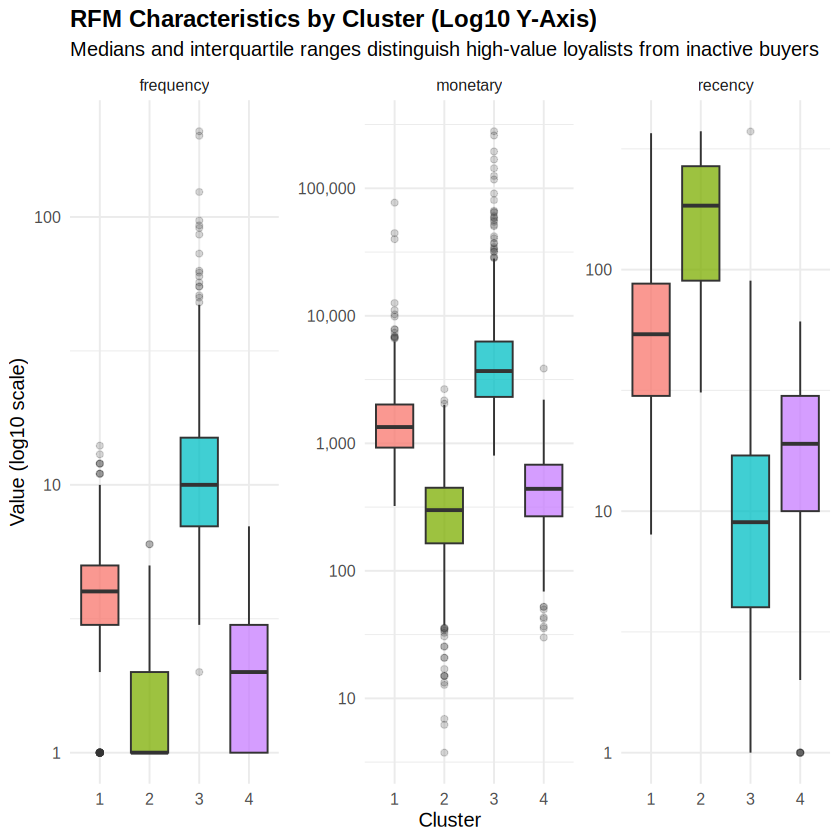

In [53]:
# 1. Cluster profile summary table
cluster_profile <- rfm_clustered %>%
  group_by(cluster) %>%
  summarise(
    n_customers      = n(),
    customer_share   = round(n() / nrow(rfm_clustered) * 100, 1),
    median_recency   = round(median(recency), 1),
    median_frequency = round(median(frequency), 1),
    median_monetary  = round(median(monetary), 1),
    mean_recency     = round(mean(recency), 1),
    mean_frequency   = round(mean(frequency), 1),
    mean_monetary    = round(mean(monetary), 1),
    total_revenue    = round(sum(monetary), 0),
    revenue_share    = round(sum(monetary) / sum(rfm_clustered$monetary) * 100, 1),
    .groups          = "drop"
  ) %>%
  arrange(desc(median_monetary))

print(cluster_profile)

# 2. Faceted boxplot comparing RFM across clusters
rfm_clustered %>%
  pivot_longer(cols = c(recency, frequency, monetary), names_to = "metric", values_to = "value") %>%
  ggplot(aes(x = cluster, y = value, fill = cluster)) +
  geom_boxplot(alpha = 0.75, outlier.alpha = 0.2) +
  facet_wrap(~ metric, scales = "free_y") +
  scale_y_log10(labels = comma) +
  labs(
    title    = "RFM Characteristics by Cluster (Log10 Y-Axis)",
    subtitle = "Medians and interquartile ranges distinguish high-value loyalists from inactive buyers",
    x        = "Cluster",
    y        = "Value (log10 scale)"
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"), legend.position = "none")

In [54]:
# 1. Print monetary & revenue-share columns of cluster_profile
cluster_profile %>%
  select(cluster, n_customers, customer_share, median_monetary, mean_monetary, total_revenue, revenue_share) %>%
  print()

# 2. Phase 8A: Spearman rank correlation among RFM variables
# (Preferred over Pearson because Frequency and Monetary are strongly right-skewed)
cat("\n--- Spearman Rank Correlations (RFM) ---\n")
print(round(cor(select(rfm, recency, frequency, monetary), method = "spearman"), 3))

# 3. Phase 8B: Kruskal-Wallis test comparing Monetary spend across clusters
kw_test <- kruskal.test(monetary ~ cluster, data = rfm_clustered)
cat("\n--- Kruskal-Wallis Test: Monetary Spend ~ Cluster ---\n")
print(kw_test)

# A tibble: 4 × 7
  cluster n_customers customer_share median_monetary mean_monetary total_revenue
  <fct>         <int>          <dbl>           <dbl>         <dbl>         <dbl>
1 3               728           16.8           3688.         7952.       5788710
2 1              1163           26.8           1342.         1802.       2095526
3 4               876           20.2            440.          516.        451892
4 2              1571           36.2            299.          351.        551081
# ℹ 1 more variable: revenue_share <dbl>

--- Spearman Rank Correlations (RFM) ---
          recency frequency monetary
recency     1.000    -0.563   -0.482
frequency  -0.563     1.000    0.807
monetary   -0.482     0.807    1.000

--- Kruskal-Wallis Test: Monetary Spend ~ Cluster ---

	Kruskal-Wallis rank sum test

data:  monetary by cluster
Kruskal-Wallis chi-squared = 3078.3, df = 3, p-value < 2.2e-16

# A tibble: 4 × 7
  cluster n_customers customer_share median_monetary mean_monetary to

In [55]:
# 1. Print exact revenue_share for all 4 clusters
cluster_profile %>%
  select(cluster, n_customers, customer_share, total_revenue, revenue_share) %>%
  print()

# 2. Assign evidence-based segment labels
rfm_segmented <- rfm_clustered %>%
  mutate(
    segment = case_when(
      cluster == "3" ~ "High-Value Loyalists",
      cluster == "1" ~ "Mid-Tier Regulars",
      cluster == "4" ~ "Recent Low-Frequency",
      cluster == "2" ~ "Inactive / One-Time"
    )
  )

cat("\nSegment counts:\n")
print(table(rfm_segmented$segment))

# 3. Export summary tables
write_csv(cleaning_audit, "cleaning_audit.csv")
write_csv(cluster_profile, "cluster_profile.csv")
write_csv(rfm_segmented, "rfm_segmented.csv")

cat("\nExported: cleaning_audit.csv, cluster_profile.csv, rfm_segmented.csv\n")

# A tibble: 4 × 5
  cluster n_customers customer_share total_revenue revenue_share
  <fct>         <int>          <dbl>         <dbl>         <dbl>
1 3               728           16.8       5788710          65.1
2 1              1163           26.8       2095526          23.6
3 4               876           20.2        451892           5.1
4 2              1571           36.2        551081           6.2

Segment counts:

High-Value Loyalists  Inactive / One-Time    Mid-Tier Regulars 
                 728                 1571                 1163 
Recent Low-Frequency 
                 876 

Exported: cleaning_audit.csv, cluster_profile.csv, rfm_segmented.csv
